<a href="https://colab.research.google.com/github/anitapore76-ai/AI-ML-Journey/blob/main/Mall-Customer-Behaviour-Analysis-Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [146]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv('/content/archive (1).zip')
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [147]:
df.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [148]:
df.index

RangeIndex(start=0, stop=200, step=1)

In [149]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [150]:
count = df.value_counts().astype('int8')
count

,,,,,count
CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),
1,Male,19,15,39,1
2,Male,21,15,81,1
3,Female,20,16,6,1
4,Female,23,16,77,1
5,Female,31,17,40,1
...,...,...,...,...,...
196,Female,35,120,79,1
197,Female,45,126,28,1
198,Male,32,126,74,1


In [151]:
df.isnull().dropna()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
195,False,False,False,False,False
196,False,False,False,False,False
197,False,False,False,False,False
198,False,False,False,False,False


In [152]:
df.duplicated().drop_duplicates()

,0
0,False


In [153]:
df['Age'].value_counts()

,count
Age,
32,11
35,9
31,8
19,8
30,7
49,7
23,6
40,6
36,6


In [154]:
df['Genre'].value_counts()

,count
Genre,
Female,112
Male,88


In [155]:
df.shape

(200, 5)

In [156]:
df['Annual Income (k$)'].astype('int8')

,Annual Income (k$)
0,15
1,15
2,16
3,16
4,17
...,...
195,120
196,126
197,126
198,-119


In [157]:
df['Genre'].dtype

dtype('O')

In [158]:
df[df['Age']<=0].sum()

,0
CustomerID,0
Genre,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


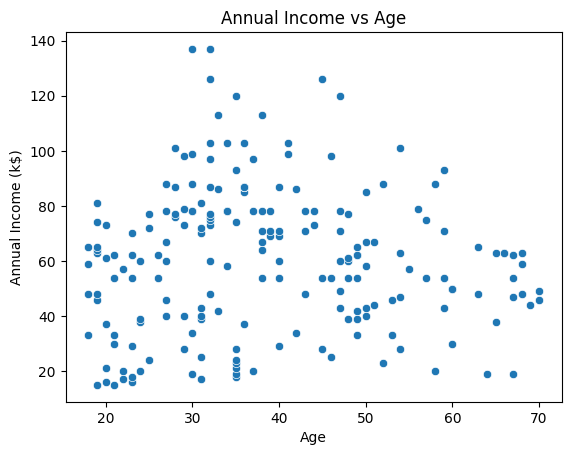

In [159]:
sns.scatterplot(x='Age',y='Annual Income (k$)',data=df)
plt.title('Annual Income vs Age')
plt.xlabel('Age')
plt.ylabel('Annual Income (k$)')
plt.show()

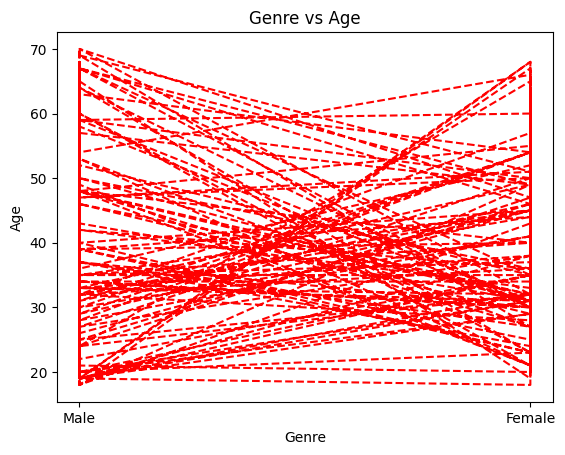

In [160]:
plt.plot(df['Genre'],df['Age'],color='red',linestyle='--')
plt.title('Genre vs Age')
plt.xlabel('Genre')
plt.ylabel('Age')
plt.show()

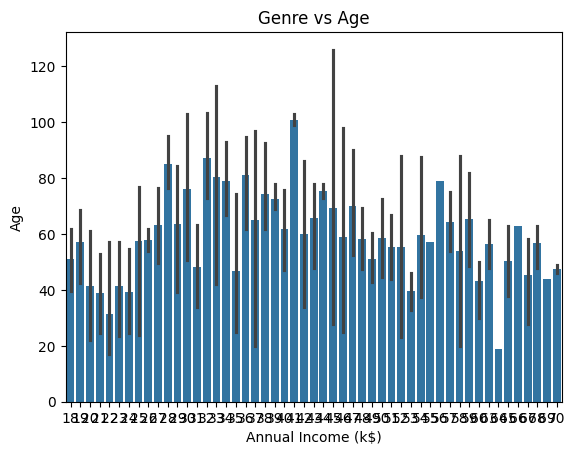

In [161]:
sns.barplot(x='Age',y='Annual Income (k$)',data=df)
plt.title('Genre vs Age')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Age')
plt.show()

<Axes: xlabel='Genre', ylabel='count'>

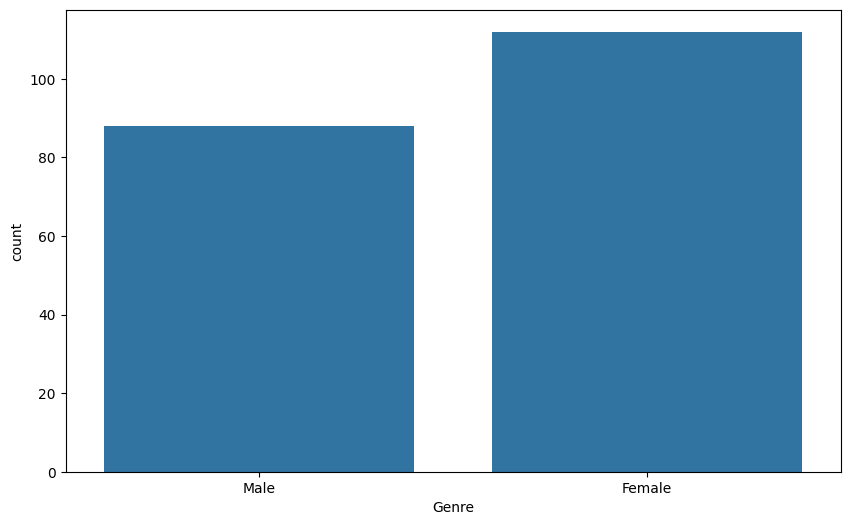

In [162]:
plt.figure(figsize=(10,6))
sns.countplot(x='Genre',data=df)

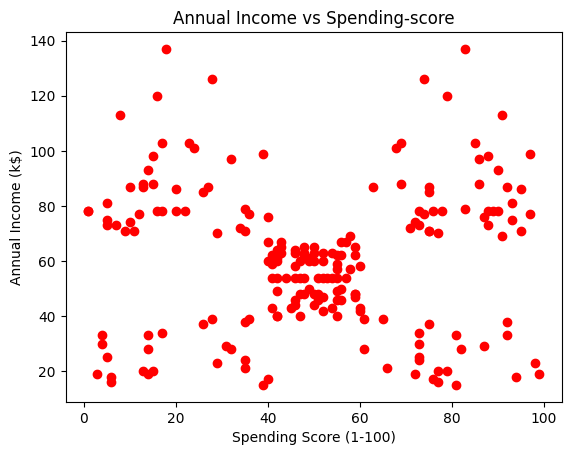

In [163]:
plt.scatter(df['Spending Score (1-100)'],df['Annual Income (k$)'],color='red')
plt.title('Annual Income vs Spending-score')
plt.xlabel('Spending Score (1-100)')
plt.ylabel('Annual Income (k$)')
plt.show()

In [164]:
correlation = df.select_dtypes(include=['int64','float64']).corr()
correlation

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
CustomerID,1.000000,-0.026763,0.977548,0.013835
Age,-0.026763,1.000000,-0.012398,-0.327227
Annual Income (k$),0.977548,-0.012398,1.000000,0.009903
Spending Score (1-100),0.013835,-0.327227,0.009903,1.000000


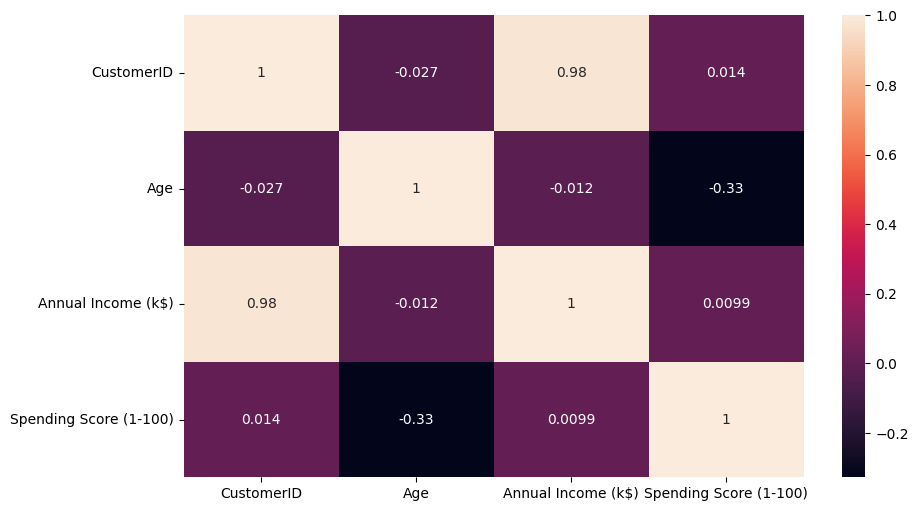

In [165]:
plt.figure(figsize=(10,6))
sns.heatmap(correlation,annot=True)
plt.show()

In [166]:
df['Age'].mean()

np.float64(38.85)

In [167]:
df['Annual Income (k$)'].mean()

np.float64(60.56)

In [168]:
df['Customer_Category'] = np.where(
    (df['Annual Income (k$)'] > 50) & (df['Spending Score (1-100)'] > 50),
    'Target Customers',

    np.where(
        (df['Annual Income (k$)'] > 50) & (df['Spending Score (1-100)'] <= 50),
        'Careful Customers',

        np.where(
            (df['Annual Income (k$)'] <= 50) & (df['Spending Score (1-100)'] > 50),
            'Impulsive Customers',

            'Low-Budget Customers'
        )
    )
)


print(df[['Annual Income (k$)',
          'Spending Score (1-100)',
          'Customer_Category']].head(10))
print(df['Customer_Category'].value_counts())

   Annual Income (k$)  Spending Score (1-100)     Customer_Category
0                  15                      39  Low-Budget Customers
1                  15                      81   Impulsive Customers
2                  16                       6  Low-Budget Customers
3                  16                      77   Impulsive Customers
4                  17                      40  Low-Budget Customers
5                  17                      76   Impulsive Customers
6                  18                       6  Low-Budget Customers
7                  18                      94   Impulsive Customers
8                  19                       3  Low-Budget Customers
9                  19                      72   Impulsive Customers
Customer_Category
Careful Customers       67
Target Customers        59
Impulsive Customers     38
Low-Budget Customers    36
Name: count, dtype: int64


In [169]:
print(df.columns.tolist())

['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Customer_Category']


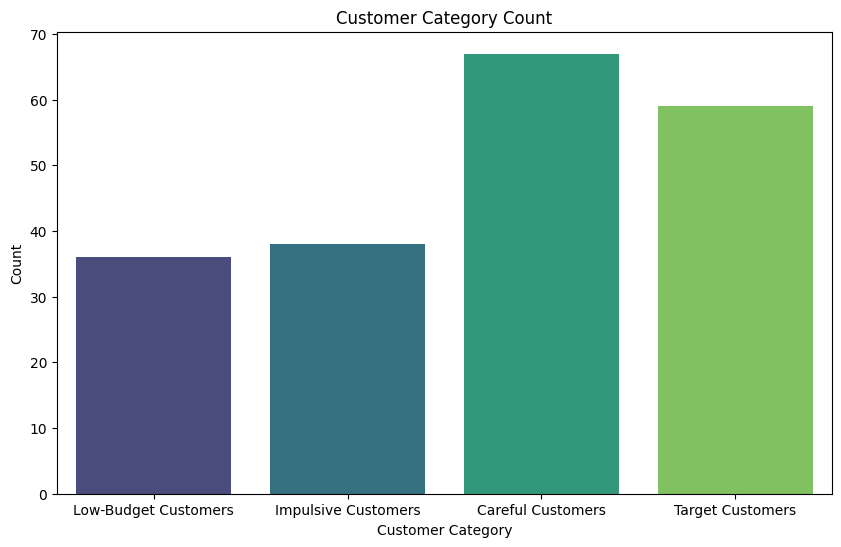

In [170]:
plt.figure(figsize=(10,6))
sns.countplot(x='Customer_Category',data=df,hue='Customer_Category',palette='viridis',legend=False)
plt.xlabel('Customer Category')
plt.ylabel('Count')
plt.title('Customer Category Count')
plt.show()

<Figure size 1500x1000 with 0 Axes>

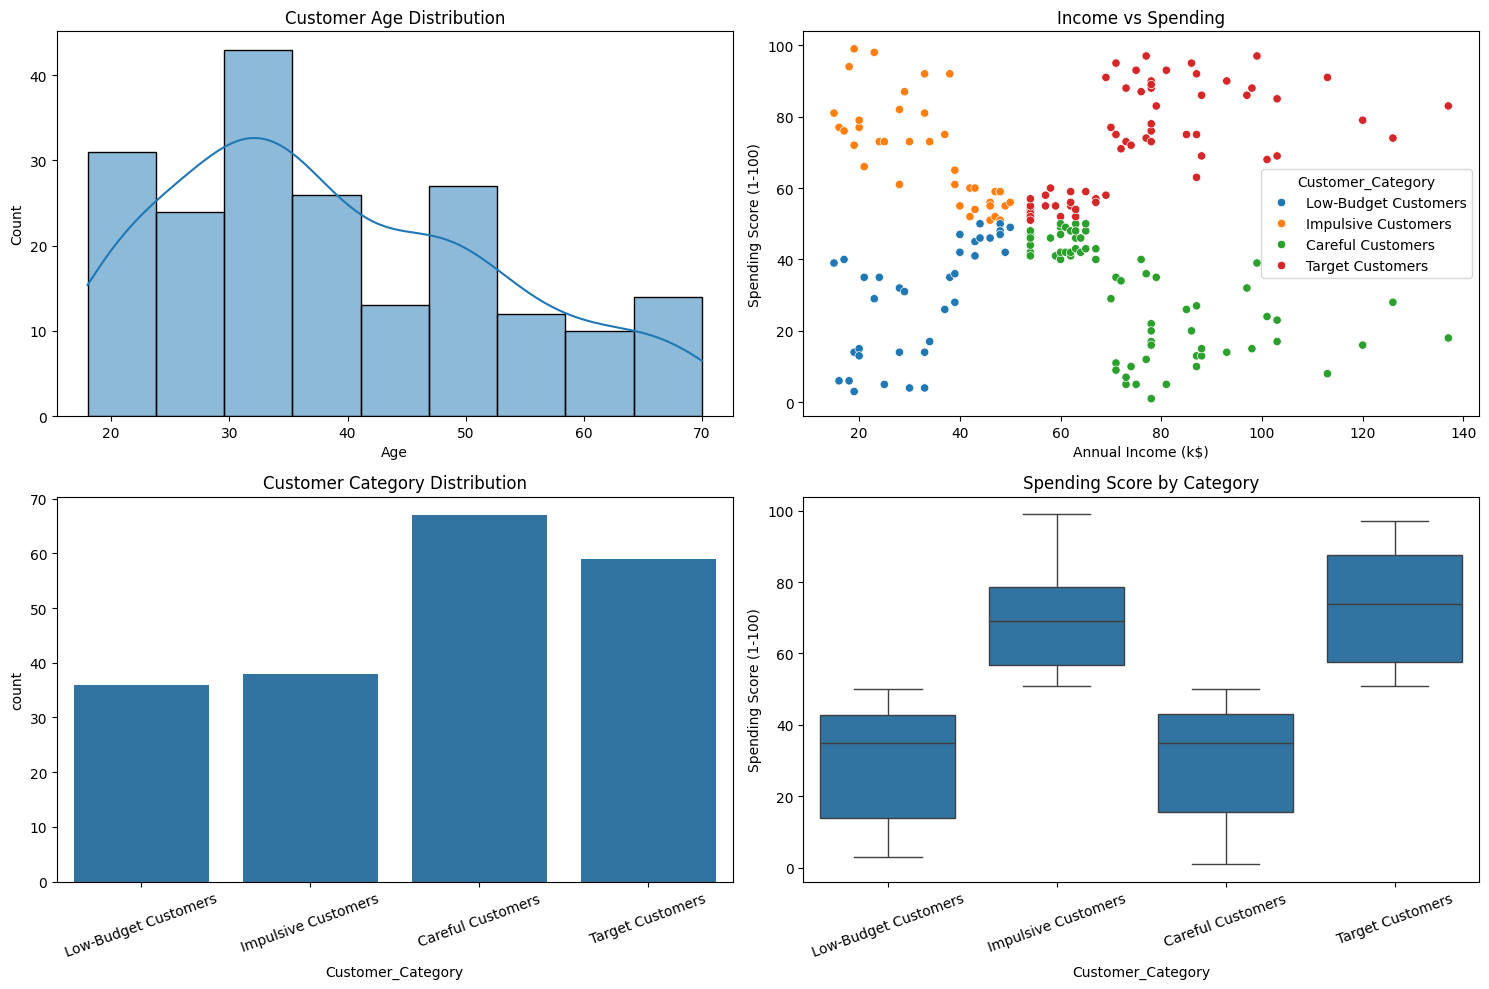

In [171]:
plt.figure(figsize=(15, 10))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Graph 1: Age distribution
sns.histplot(
    data=df,
    x='Age',
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title('Customer Age Distribution')

# Graph 2: Income vs Spending
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Customer_Category',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Income vs Spending')

# Graph 3: Customer categories
sns.countplot(
    data=df,
    x='Customer_Category',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Customer Category Distribution')
axes[1, 0].tick_params(axis='x', rotation=20)

# Graph 4: Spending score by category
sns.boxplot(
    data=df,
    x='Customer_Category',
    y='Spending Score (1-100)',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Spending Score by Category')
axes[1, 1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

In [172]:
fig.savefig('mall_customer_dashboard.png', dpi=300, bbox_inches='tight')

In [175]:
print("""
PROJECT CONCLUSION

The Mall Customer Behaviour Analysis project helped me understand customer purchasing patterns using Python.

In this project, I used four Python libraries:
1. Pandas – Data manipulation and analysis.
2. NumPy – Numerical and statistical calculations.
3. Matplotlib – Data visualization.
4. Seaborn – Statistical visualization.

I analysed customer age, annual income, and spending scores.
I created four customer categories based on income and spending behaviour.
I also developed visualizations and a final dashboard.

Through this project, I gained practical knowledge of data cleaning,
exploratory data analysis (EDA), statistical analysis, and data visualization.

This project demonstrates how data analysis can transform raw data
into meaningful insights for business decision-making.
""")


PROJECT CONCLUSION

The Mall Customer Behaviour Analysis project helped me understand customer purchasing patterns using Python.

In this project, I used four Python libraries:
1. Pandas – Data manipulation and analysis.
2. NumPy – Numerical and statistical calculations.
3. Matplotlib – Data visualization.
4. Seaborn – Statistical visualization.

I analysed customer age, annual income, and spending scores.
I created four customer categories based on income and spending behaviour.
I also developed visualizations and a final dashboard.

Through this project, I gained practical knowledge of data cleaning,
exploratory data analysis (EDA), statistical analysis, and data visualization.

This project demonstrates how data analysis can transform raw data
into meaningful insights for business decision-making.

